# ML Assignment 2 — Classification Models (Breast Cancer Wisconsin)

**How to use this notebook (Google Colab):** click **Runtime → Run all**. Every result appears below each cell.
At the end it creates the files you need for GitHub (the 5 saved models and `test_data.csv`) and downloads them as one zip.

What it does, in order:
1. Loads the dataset (569 rows, 30 features, binary: Benign / Malignant)
2. Splits it 80 / 20 and saves the 20 % as `test_data.csv`
3. Trains Logistic Regression, Decision Tree, KNN, Naive Bayes and SVM
4. Calculates Accuracy, AUC, Precision, Recall, F1 and MCC for each model
5. Shows confusion matrices, classification reports and ROC curves
6. Saves the trained models in the `model/` folder and downloads everything

## 1. Imports

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, matthews_corrcoef, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


## 2. Settings
`SEED` makes the split and models reproducible. Change it (and the model settings in step 5) to your own values.

In [2]:
SEED = 2026
TEST_SIZE = 0.20
TARGET_COLUMN = "diagnosis"
CLASS_NAMES = {0: "Benign", 1: "Malignant"}

MODEL_DIR = Path("model")          # saved models go here
MODEL_DIR.mkdir(exist_ok=True)

## 3. Load the dataset
Breast Cancer Wisconsin (Diagnostic) — originally from the UCI repository and bundled with scikit-learn.
We flip the label so that **1 = Malignant** (the class we most want to detect).

*To use your own Kaggle / UCI dataset instead, replace this cell's code with `df = pd.read_csv("your_file.csv")`
(upload the file in the Colab Files panel first) and make sure the label column is named in `TARGET_COLUMN`.*

In [3]:
df = load_breast_cancer(as_frame=True).frame
df[TARGET_COLUMN] = 1 - df["target"]            # 1 = Malignant, 0 = Benign
df = df.drop(columns=["target"])
df.columns = [c.replace(" ", "_") for c in df.columns]

print(f"Rows: {len(df)} | Features: {df.shape[1] - 1} | Missing values: {df.isna().sum().sum()}")
print(df[TARGET_COLUMN].map(CLASS_NAMES).value_counts().to_string())
df.head()

Rows: 569 | Features: 30 | Missing values: 0
diagnosis
Benign       357
Malignant    212


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,...,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 4. Train / test split and `test_data.csv`

In [4]:
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

# test_data.csv = features + target. This is the file you upload in the Streamlit app.
pd.concat([X_test, y_test], axis=1).to_csv("test_data.csv", index=False)

print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
print("Saved test_data.csv")

Training rows: 455 | Test rows: 114
Saved test_data.csv


## 5. Define and train the five models
`StandardScaler` is inside a `Pipeline` for Logistic Regression, KNN and SVM (they are sensitive to feature scale).
Decision Tree and Naive Bayes do not need scaling.

In [5]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED))]),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=3, random_state=SEED),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=7))]),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", C=1.0, probability=True, random_state=SEED))]),
}

def file_name(name):
    return name.lower().replace(" ", "_") + ".joblib"

for name, model in models.items():
    model.fit(X_train, y_train)
    joblib.dump(model, MODEL_DIR / file_name(name))
    print(f"trained and saved: {MODEL_DIR / file_name(name)}")

trained and saved: model/logistic_regression.joblib
trained and saved: model/decision_tree.joblib
trained and saved: model/knn.joblib
trained and saved: model/naive_bayes.joblib
trained and saved: model/support_vector_machine.joblib


## 6. Evaluation metrics on the test set

In [6]:
def evaluate(model, X, y):
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    return {
        "Accuracy": accuracy_score(y, pred),
        "AUC": roc_auc_score(y, proba),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "MCC": matthews_corrcoef(y, pred),
    }

results = pd.DataFrame(
    [{"ML Model Name": name, **evaluate(m, X_test, y_test)} for name, m in models.items()]
).set_index("ML Model Name")

try:
    display(results.style.format("{:.4f}").highlight_max(color="#c7e9c0"))
except Exception:
    display(results.round(4))

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9737,0.9987,0.9756,0.9524,0.9639,0.9433
Decision Tree,0.9737,0.9785,0.9756,0.9524,0.9639,0.9433
KNN,0.9737,0.9974,0.9535,0.9762,0.9647,0.9439
Naive Bayes,0.9474,0.9927,0.9286,0.9286,0.9286,0.8869
Support Vector Machine,0.9825,1.0000,0.9545,1.0000,0.9767,0.9633


The green cell is the best value in each column.
**Positive class = Malignant**, so Recall tells you how many malignant cases the model caught.

In [7]:
best = results.idxmax()
print("Best model per metric:")
print(best.to_string())
print("\nWinner by MCC:", results["MCC"].idxmax())

Best model per metric:
Accuracy     Support Vector Machine
AUC          Support Vector Machine
Precision       Logistic Regression
Recall       Support Vector Machine
F1           Support Vector Machine
MCC          Support Vector Machine

Winner by MCC: Support Vector Machine


## 7. Confusion matrices

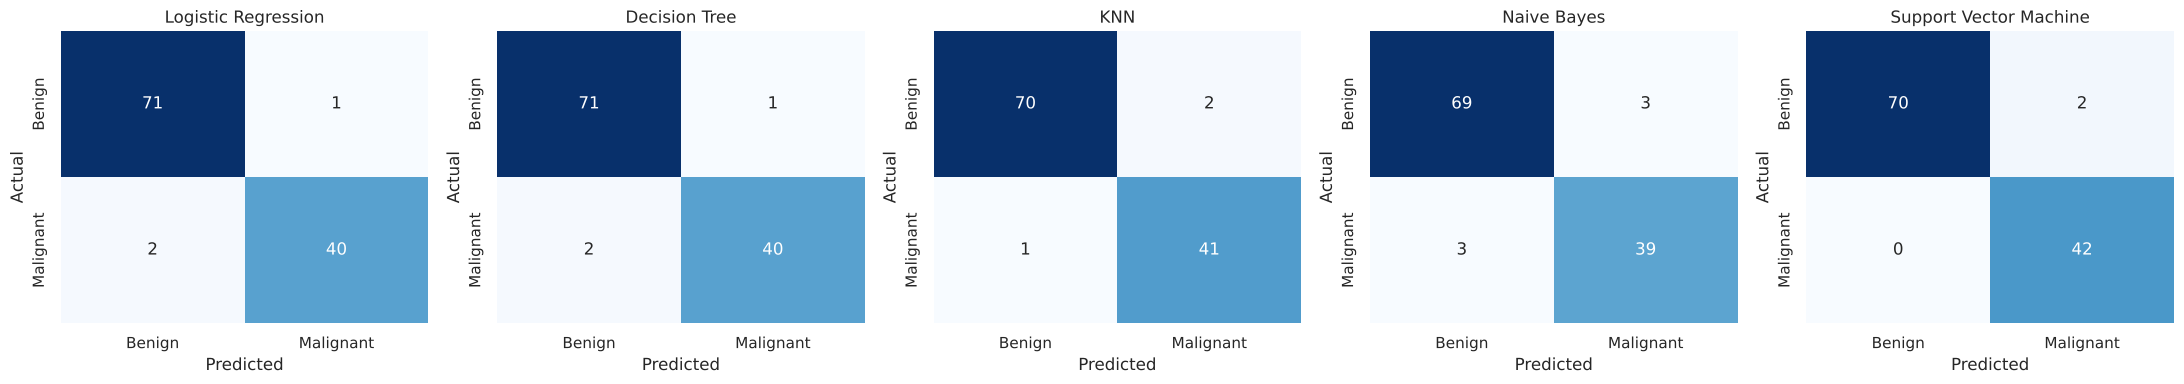

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
labels = [CLASS_NAMES[0], CLASS_NAMES[1]]
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

Reading a matrix: top-left = benign correctly found, bottom-right = malignant correctly found,
top-right = **false positives** (benign called malignant), bottom-left = **false negatives** (malignant missed).

In [9]:
errors = []
for name, model in models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, model.predict(X_test)).ravel()
    errors.append({"ML Model Name": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp, "Total errors": fp + fn})
pd.DataFrame(errors).set_index("ML Model Name")

,TN,FP,FN,TP,Total errors
ML Model Name,,,,,
Logistic Regression,71,1,2,40,3
Decision Tree,71,1,2,40,3
KNN,70,2,1,41,3
Naive Bayes,69,3,3,39,6
Support Vector Machine,70,2,0,42,2


## 8. Classification reports

In [10]:
for name, model in models.items():
    print("=" * 60)
    print(name)
    print(classification_report(y_test, model.predict(X_test), target_names=labels, digits=4))

Logistic Regression
              precision    recall  f1-score   support

      Benign     0.9726    0.9861    0.9793        72
   Malignant     0.9756    0.9524    0.9639        42

    accuracy                         0.9737       114
   macro avg     0.9741    0.9692    0.9716       114
weighted avg     0.9737    0.9737    0.9736       114

Decision Tree
              precision    recall  f1-score   support

      Benign     0.9726    0.9861    0.9793        72
   Malignant     0.9756    0.9524    0.9639        42

    accuracy                         0.9737       114
   macro avg     0.9741    0.9692    0.9716       114
weighted avg     0.9737    0.9737    0.9736       114

KNN
              precision    recall  f1-score   support

      Benign     0.9859    0.9722    0.9790        72
   Malignant     0.9535    0.9762    0.9647        42

    accuracy                         0.9737       114
   macro avg     0.9697    0.9742    0.9719       114
weighted avg     0.9740    0.9737   

## 9. ROC curves

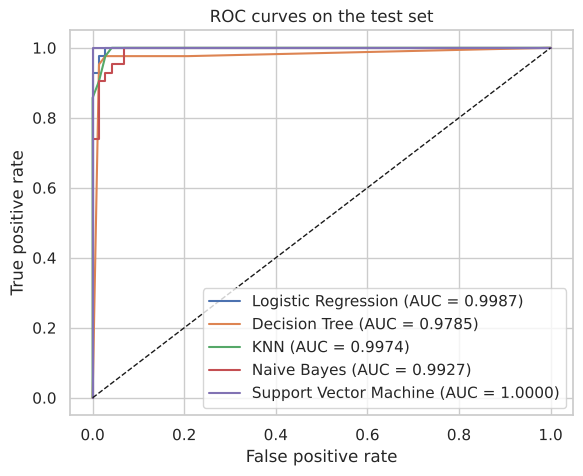

In [11]:
plt.figure(figsize=(6.5, 5))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results.loc[name, 'AUC']:.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves on the test set")
plt.legend(loc="lower right")
plt.show()

## 10. Check that the saved models work without retraining
This is exactly what the Streamlit app does: **load** the saved `.joblib` file, read `test_data.csv`, and compute the metrics.
The numbers must match the table above.

In [12]:
test_df = pd.read_csv("test_data.csv")
X_check, y_check = test_df.drop(columns=[TARGET_COLUMN]), test_df[TARGET_COLUMN]

reloaded = pd.DataFrame(
    [{"ML Model Name": name, **evaluate(joblib.load(MODEL_DIR / file_name(name)), X_check, y_check)}
     for name in models]
).set_index("ML Model Name")

print("Reloaded models give identical results:", np.allclose(reloaded.values, results.values))
reloaded.round(4)

Reloaded models give identical results: True


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9737,0.9987,0.9756,0.9524,0.9639,0.9433
Decision Tree,0.9737,0.9785,0.9756,0.9524,0.9639,0.9433
KNN,0.9737,0.9974,0.9535,0.9762,0.9647,0.9439
Naive Bayes,0.9474,0.9927,0.9286,0.9286,0.9286,0.8869
Support Vector Machine,0.9825,1.0000,0.9545,1.0000,0.9767,0.9633


## 11. Copy-paste table for your README
Paste this into the *Comparison table* section of `README.md`.

In [13]:
print("| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |")
print("|---|---|---|---|---|---|---|")
for name, row in results.iterrows():
    print(f"| {name} | " + " | ".join(f"{row[c]:.4f}" for c in results.columns) + " |")

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.9737 | 0.9987 | 0.9756 | 0.9524 | 0.9639 | 0.9433 |
| Decision Tree | 0.9737 | 0.9785 | 0.9756 | 0.9524 | 0.9639 | 0.9433 |
| KNN | 0.9737 | 0.9974 | 0.9535 | 0.9762 | 0.9647 | 0.9439 |
| Naive Bayes | 0.9474 | 0.9927 | 0.9286 | 0.9286 | 0.9286 | 0.8869 |
| Support Vector Machine | 0.9825 | 1.0000 | 0.9545 | 1.0000 | 0.9767 | 0.9633 |


## 12. Package the files and download them
The zip contains `test_data.csv` and the `model/` folder with the 5 `.joblib` files.
These go into your GitHub repository (see the instructions below this cell's output).

**Important:** the line printed below goes into `requirements.txt` so that Streamlit Cloud uses the same
scikit-learn version that saved these models.

In [14]:
import shutil
print("Put this line in requirements.txt  ->  scikit-learn==" + sklearn.__version__)

shutil.make_archive("assignment_files", "zip", root_dir=".", base_dir="model")   # model/ folder
import zipfile
with zipfile.ZipFile("assignment_files.zip", "a") as z:
    z.write("test_data.csv")                                                      # + test_data.csv

with zipfile.ZipFile("assignment_files.zip") as z:
    print("\nFiles in assignment_files.zip:")
    for n in z.namelist():
        print("  ", n)

try:
    from google.colab import files
    files.download("assignment_files.zip")
except ImportError:
    print("\n(Not running in Colab - the zip is saved next to this notebook.)")

Put this line in requirements.txt  ->  scikit-learn==1.9.1

Files in assignment_files.zip:
   model/
   model/decision_tree.joblib
   model/knn.joblib
   model/logistic_regression.joblib
   model/naive_bayes.joblib
   model/support_vector_machine.joblib
   test_data.csv

(Not running in Colab - the zip is saved next to this notebook.)


## What to do next

Your GitHub repository must look like this:

```
your-repo/
├── app.py                 (from the project folder I gave you)
├── requirements.txt       (with the scikit-learn line printed above)
├── README.md
├── test_data.csv          (from assignment_files.zip)
└── model/
    ├── logistic_regression.joblib      (from assignment_files.zip)
    ├── decision_tree.joblib
    ├── knn.joblib
    ├── naive_bayes.joblib
    ├── support_vector_machine.joblib
    └── model_training.ipynb            (this notebook - it is your source code)
```

Then deploy `app.py` on Streamlit Community Cloud.